# Synthetic Respiratory DISEASES (Hypoxia Mechanisms) + Classification  
**Author:** Sergio Pascual Redondo  
**Date:** 10-02-2026  

## Goal
Build a *tabular* synthetic dataset to classify **hypoxia mechanisms and chronic respiratory patterns** using Machine Learning.

## Labels
`label ∈ {healthy, hypoxia_altitude, hypoxia_anemic, asthma, edema, fibrosis, emphysema}`

## Features (15)
- **Age** (years)
- **HR** (heart rate, bpm)
- **RR** (respiratory rate, breaths/min)

### Gas exchange & ventilation
- **SpO2** (pulse oximetry saturation, %)
- **PaCO2** (arterial CO₂ partial pressure, mmHg)

### Acid–base
- **pH**
- **HCO3** (bicarbonate, mEq/L)

### O₂ transport (anemia vs hypoxemia)
- **Hb** (hemoglobin concentration, g/dL)
- **CaO2** (arterial oxygen content, mL O₂/dL)

### Obstruction / restriction
- **AirwayResistance** (obstruction proxy; asthma/emphysema)
- **FEV1_FVC** (spirometry ratio; obstruction vs restriction patterns)
- **DLCO_percent** (diffusion capacity, % predicted; fibrosis/emphysema)

### Imaging / congestion
- **CXR_score** (chest X-ray severity score, 0–12)
- **B_lines** (lung ultrasound B-lines; interstitial/alveolar involvement)
- **BNP** (natriuretic peptide, pg/mL; congestion proxy, strongest in edema)

> **Note:** The dataset is synthetic but physiology-inspired. We purposely introduce **correlations, noise, and overlap** between classes (no “hard rules”), and we keep the dataset **imbalanced** (more healthy subjects) to mimic real clinical prevalence and motivate the use of **stratified splitting** and **per-class metrics** (macro precision/recall/F1).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
SEED = 42
np.random.seed(SEED)



## How the synthetic data are generated (brief)

For each class we sample a latent **severity** variable (`severity ~ Beta(2, 4.5)`) to create realistic variability **within** each label. Then we generate the features using physiology-inspired relationships (plus measurement noise), so classes are **not** separated by “hard rules”.

### Class-specific mechanisms (what we emulate)

- **Healthy:** normal ranges for gas exchange and cardiorespiratory response. The **A–a gradient** is small, and imaging findings are minimal (low `B_lines`, low `CXR_score`).

- **Hypoxia (Altitude):** the primary driver is reduced inspired oxygen due to **lower barometric pressure** (internally sampled `Pbar`).  
  This lowers **alveolar oxygen** (`PAO2`), while the **A–a gradient remains small** (i.e., lungs are not the main problem). Mild hyperventilation is emulated with **lower `PaCO2`**.

- **Hypoxia (Anemic):** oxygenation in the lungs can be relatively preserved (small/normal A–a), but the limiting factor is **low hemoglobin (`Hb`)**, reducing oxygen-carrying capacity. We also add mild **tachycardia (`HR`)** and **tachypnea (`RR`)** tendencies with severity.

- **Hypoxia (Asthma / Obstructive):** modeled as increased **airway obstruction** via higher `AirwayResistance`, with **higher RR/HR**. Gas exchange worsens through V/Q mismatch, reflected by a **moderate A–a gradient** and occasional **CO₂ retention** in severe cases.

- **Hypoxia (Pulmonary edema):** modeled as increased interstitial/alveolar water (latent `lung_water` derived from severity). Imaging evidence increases via **higher `B_lines`** and **higher `CXR_score`**, and oxygenation worsens via a **large A–a gradient** (shunt/VQ effects).

- **Hypoxia (Fibrosis):** modeled as chronic interstitial disease with increased `CXR_score` and **moderately increased `B_lines`** (overlapping with edema but typically less extreme). We emulate a tendency to **hyperventilation** (lower `PaCO2`) and a **moderate-to-high A–a gradient** due to diffusion limitation.

- **Hypoxia (Emphysema):** modeled as chronic obstructive disease with increased `AirwayResistance`, low-to-moderate imaging changes (typically **low `B_lines`**), and a tendency toward **CO₂ retention** (higher `PaCO2`) with partial metabolic compensation (slightly higher `HCO3`). The A–a gradient is **moderate** (V/Q mismatch + loss of effective surface).

### Coherence constraints (physiology-inspired coupling)

- **Alveolar oxygen (`PAO2`)** is generated internally using a simplified alveolar gas relationship:
  - `PiO2 = FiO2 * (Pbar - 47)`
  - `PAO2 = PiO2 - PaCO2 / 0.8`
  (`Pbar` and `PiO2` are used internally but **not stored** to reduce feature redundancy.)

- **Acid–base** is coupled to ventilation:
  - `pH` is computed from `PaCO2` and `HCO3` using a soft physiological relationship + small noise.

- **SpO2** is produced from an internal arterial oxygen (`PaO2`) using a smooth Hb–O₂ dissociation approximation:
  - `PaO2` is generated as `PAO2 - (A–a gradient) + noise`
  - `SpO2` is generated from `PaO2` via a sigmoid-like saturation curve + noise  
  (`PaO2` is computed internally but **not stored**; we keep `SpO2` as the clinical oxygenation feature.)

### Important design choice
We explicitly inject **noise and overlap** (and keep the dataset **imbalanced with more healthy subjects**) so the task cannot be solved by simple if/else rules and requires ML models + robust evaluation (e.g., macro metrics and confusion matrices).


In [ ]:
# --- FULL synthetic dataset creation (physiology-inspired, realistic + overlap) ---




def _spo2_from_pao2(pao2: np.ndarray) -> np.ndarray:
    """
    Approx Severinghaus-like saturation curve.
    Key property: PaO2 ~ 60 mmHg -> SpO2 ~ ~90% (not 50%).
    """
    pao2 = np.clip(pao2, 1e-3, 200)
    return 100.0 * (pao2**3 + 150.0 * pao2) / (pao2**3 + 150.0 * pao2 + 23400.0)


def generate_pulmonary_synthetic_dataset(n_per_class=None, seed: int = 42) -> pd.DataFrame:
    """
    Create a multi-class pulmonary dataset with realistic ranges, randomness, and overlap.
    Labels:
      - healthy
      - hypoxia_altitude
      - hypoxia_anemic
      - asthma
      - edema
      - fibrosis
      - emphysema

    Output columns (15 features + label):
      Age, HR, RR, SpO2, PaCO2, HCO3, pH, Hb, CaO2,
      AirwayResistance, FEV1_FVC, DLCO_percent, B_lines, CXR_score, BNP, label
    """
    if n_per_class is None:
        # Intentionally imbalanced (more healthy), to avoid trivial accuracy-only evaluation later
        n_per_class = {
            "healthy": 900,
            "hypoxia_altitude": 250,
            "hypoxia_anemic": 220,
            "asthma": 260,
            "edema": 180,
            "fibrosis": 160,
            "emphysema": 180,
        }

    rng = np.random.default_rng(seed)
    rows = []

    for label, n in n_per_class.items():
        # 1) Latent severity drives within-class variability (skewed toward mild)
        severity = rng.beta(2, 4.5, size=n)
        if label in ("edema", "emphysema", "fibrosis"):
            severity = np.clip(severity * 1.15 + 0.05, 0, 1)
        elif label == "asthma":
            severity = np.clip(severity * 1.05 + 0.02, 0, 1)

        # 2) Age: label-dependent but overlapping (no hard separation)
        age_mu = {
            "healthy": 35, "hypoxia_altitude": 28, "hypoxia_anemic": 46,
            "asthma": 30, "edema": 72, "fibrosis": 66, "emphysema": 69
        }[label]
        age_sd = {
            "healthy": 14, "hypoxia_altitude": 10, "hypoxia_anemic": 16,
            "asthma": 13, "edema": 11, "fibrosis": 11, "emphysema": 10
        }[label]
        Age = np.clip(rng.normal(age_mu, age_sd, size=n), 18, 90)

        # 3) Internal barometric pressure Pbar (mmHg) for alveolar gas equation
        # NOTE: NOT stored as a feature (prevents "altitude is obvious" shortcuts).
        if label == "hypoxia_altitude":
            Pbar = np.clip(rng.normal(610, 35, size=n), 520, 700)  # moderate altitude range
        else:
            Pbar = np.clip(rng.normal(760, 12, size=n), 700, 790)

        # 4) Latent physiology factors (overlap + noise)
        # obstruction -> affects airway metrics + CO2 retention + spirometry
        # lung_water  -> affects B-lines/CXR + oxygenation
        # diffusion   -> affects DLCO + oxygenation (fibrosis/emphysema)
        obstruction_base = {
            "healthy": 0.10, "hypoxia_altitude": 0.12, "hypoxia_anemic": 0.12,
            "asthma": 0.60, "edema": 0.14, "fibrosis": 0.18, "emphysema": 0.65
        }[label]
        obstruction = np.clip(obstruction_base + 0.60 * severity + rng.normal(0, 0.12, size=n), 0, 1.2)

        lung_water_base = {
            "healthy": 0.08, "hypoxia_altitude": 0.10, "hypoxia_anemic": 0.10,
            "asthma": 0.12, "edema": 0.78, "fibrosis": 0.42, "emphysema": 0.12
        }[label]
        lung_water = np.clip(lung_water_base + 0.55 * severity + rng.normal(0, 0.12, size=n), 0, 1.3)

        diffusion_base = {
            "healthy": 0.10, "hypoxia_altitude": 0.12, "hypoxia_anemic": 0.12,
            "asthma": 0.12, "edema": 0.45, "fibrosis": 0.80, "emphysema": 0.60
        }[label]
        diffusion = np.clip(diffusion_base + 0.55 * severity + rng.normal(0, 0.10, size=n), 0, 1.4)

        # 5) PaCO2 (mmHg): ventilation patterns (hyperventilation vs retention)
        if label == "healthy":
            PaCO2 = rng.normal(40, 3.0, size=n)
        elif label == "hypoxia_altitude":
            PaCO2 = rng.normal(34, 3.2, size=n) - 2.5 * severity  # hyperventilation
        elif label == "hypoxia_anemic":
            PaCO2 = rng.normal(39, 3.2, size=n) - 0.8 * severity
        elif label == "fibrosis":
            PaCO2 = rng.normal(36, 3.2, size=n) - 3.5 * severity  # chronic hyperventilation tendency
        elif label == "edema":
            PaCO2 = rng.normal(38, 3.8, size=n) + 2.0 * (severity ** 1.5)  # some retention in severe
        elif label == "asthma":
            # mild: can be low; severe: retention can appear
            PaCO2 = 34 + 1.5 * severity + 12.0 * (severity ** 2) + rng.normal(0, 4.0, size=n)
        elif label == "emphysema":
            PaCO2 = 42 + 9.0 * (severity ** 1.2) + rng.normal(0, 4.2, size=n)
        PaCO2 = np.clip(PaCO2, 24, 75)

        # 6) RR and HR: severity-driven with overlap
        RR_base = {
            "healthy": 14, "hypoxia_altitude": 17, "hypoxia_anemic": 16,
            "asthma": 16, "edema": 20, "fibrosis": 19, "emphysema": 18
        }[label]
        RR = np.clip(RR_base + 9.0 * severity + rng.normal(0, 2.0, size=n), 10, 40)

        HR_base = {
            "healthy": 70, "hypoxia_altitude": 78, "hypoxia_anemic": 82,
            "asthma": 78, "edema": 88, "fibrosis": 84, "emphysema": 86
        }[label]
        HR = np.clip(HR_base + 26.0 * severity + rng.normal(0, 8.5, size=n), 45, 160)

        # 7) Hemoglobin Hb (g/dL): anemia strongest in hypoxia_anemic, overlap elsewhere
        if label == "hypoxia_anemic":
            Hb = rng.normal(9.6, 1.3, size=n) + 0.4 * rng.normal(0, 1, size=n)
        elif label == "hypoxia_altitude":
            Hb = rng.normal(14.2, 1.2, size=n) + 0.7 * severity  # mild polycythemia tendency
        elif label in ("emphysema", "fibrosis", "edema"):
            Hb = rng.normal(12.9, 1.4, size=n) + 0.3 * rng.normal(0, 1, size=n)
        else:
            Hb = rng.normal(14.0, 1.3, size=n)
        Hb = np.clip(Hb, 6.5, 18.5)

        # 8) A–a gradient (mmHg): age component + pathology component (internal; not stored)
        AA_expected = (Age / 4.0) + 4.0
        add_AA = {
            "healthy": 0.0,
            "hypoxia_altitude": 1.5,   # lungs are OK: small A-a
            "hypoxia_anemic": 2.0,     # oxygenation OK, mild noise
            "asthma": 9.0,             # V/Q mismatch
            "edema": 22.0,             # shunt/VQ
            "fibrosis": 18.0,          # diffusion limitation
            "emphysema": 12.0          # V/Q + surface loss
        }[label]
        A_a = AA_expected + add_AA * (0.35 + 0.85 * severity) + rng.normal(0, 3.5, size=n)
        A_a = A_a + rng.normal(0, 2.0, size=n) * (rng.random(n) < 0.06)  # occasional noise/outliers
        A_a = np.clip(A_a, 0, 65)

        # 9) Alveolar gas equation (internal): PAO2 -> PaO2 -> SpO2
        FiO2, PH2O, RQ = 0.21, 47.0, 0.8
        PiO2 = FiO2 * (Pbar - PH2O)
        PAO2 = PiO2 - (PaCO2 / RQ)

        PaO2 = np.clip(PAO2 - A_a + rng.normal(0, 5.0, size=n), 30, 120)

        # Realistic SpO2 curve (key fix)
        SpO2 = _spo2_from_pao2(PaO2) + rng.normal(0, 1.6, size=n)
        SpO2 = np.clip(SpO2, 55, 100)

        # 10) HCO3 (mEq/L) + pH from Henderson–Hasselbalch
        if label == "emphysema":
            HCO3 = rng.normal(27.0, 2.2, size=n) + 3.0 * (severity ** 1.1)  # chronic compensation
        elif label == "asthma":
            HCO3 = rng.normal(24.0, 2.1, size=n) + 1.0 * (severity ** 1.2)
        elif label in ("hypoxia_altitude", "fibrosis"):
            HCO3 = rng.normal(22.8, 1.9, size=n) - 0.9 * severity
        else:
            HCO3 = rng.normal(24.2, 2.0, size=n) + 0.6 * (severity ** 1.1)
        HCO3 = np.clip(HCO3, 14, 40)

        pH = 6.1 + np.log10(HCO3 / (0.03 * PaCO2)) + rng.normal(0, 0.02, size=n)
        pH = np.clip(pH, 7.02, 7.58)

        # 11) Oxygen content CaO2 (mL O2/dL): combines Hb + saturation
        CaO2 = 1.34 * Hb * (SpO2 / 100.0) + 0.003 * PaO2 + rng.normal(0, 0.35, size=n)
        CaO2 = np.clip(CaO2, 4.5, 24.5)

        # 12) Airway resistance and FEV1/FVC (class-specific realism fix)
        AirwayResistance = np.clip(1.6 + 4.6 * obstruction + rng.normal(0, 0.7, size=n), 0.8, 10.0)

        if label in ("asthma", "emphysema"):
            FEV1_FVC = 0.78 - 0.35 * obstruction + rng.normal(0, 0.05, size=n)
        elif label == "fibrosis":
            FEV1_FVC = 0.84 - 0.08 * obstruction + rng.normal(0, 0.04, size=n)
        else:
            # healthy / altitude / anemic / edema: should stay mostly normal
            FEV1_FVC = 0.80 - 0.12 * obstruction + rng.normal(0, 0.04, size=n)

        FEV1_FVC = np.clip(FEV1_FVC, 0.30, 0.92)

        # 13) DLCO % predicted: reduced in fibrosis/emphysema; asthma typically normal-ish
        DLCO_base = {
            "healthy": 92, "hypoxia_altitude": 90, "hypoxia_anemic": 88,
            "asthma": 95, "edema": 70, "fibrosis": 50, "emphysema": 45
        }[label]
        DLCO_percent = np.clip(DLCO_base - 35.0 * diffusion + rng.normal(0, 10.0, size=n), 18, 125)

        # 14) Imaging surrogates: B-lines and CXR score driven by lung_water + overlap/noise
        lam = 0.8 + 10.0 * lung_water
        lam = lam + 3.0 * (rng.random(n) < 0.06)  # occasional artifacts
        B_lines = np.clip(rng.poisson(lam=np.clip(lam, 0.2, 22.0)), 0, 30)

        CXR_mean = 0.8 + 7.5 * lung_water + 2.0 * diffusion + rng.normal(0, 1.2, size=n)
        CXR_score = np.clip(np.rint(CXR_mean), 0, 12).astype(int)

        # 15) BNP (pg/mL): edema strongest but overlaps with age/comorbidity
        if label == "edema":
            bnp_log_mu, bnp_log_sd = 5.5 + 0.65 * severity, 0.55
        elif label in ("fibrosis", "emphysema"):
            bnp_log_mu, bnp_log_sd = 4.6 + 0.30 * severity + 0.004 * (Age - 50), 0.60
        else:
            bnp_log_mu, bnp_log_sd = 3.9 + 0.18 * severity + 0.002 * (Age - 40), 0.65

        BNP = np.clip(rng.lognormal(mean=bnp_log_mu, sigma=bnp_log_sd, size=n), 5, 3500)

        rows.append(pd.DataFrame({
            "Age": Age,
            "HR": HR,
            "RR": RR,
            "SpO2": SpO2,
            "PaCO2": PaCO2,
            "HCO3": HCO3,
            "pH": pH,
            "Hb": Hb,
            "CaO2": CaO2,
            "AirwayResistance": AirwayResistance,
            "FEV1_FVC": FEV1_FVC,
            "DLCO_percent": DLCO_percent,
            "B_lines": B_lines,
            "CXR_score": CXR_score,
            "BNP": BNP,
            "label": label
        }))

    df = pd.concat(rows, ignore_index=True)
    df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df




Shape: (2150, 16)
label
healthy             900
asthma              260
hypoxia_altitude    250
hypoxia_anemic      220
emphysema           180
edema               180
fibrosis            160
Name: count, dtype: int64
         Age         HR         RR       SpO2      PaCO2       HCO3        pH  \
0  46.725958  92.326762  19.337340  95.409350  39.798677  25.481621  7.420733   
1  78.272210  92.660588  20.011368  95.693252  27.936755  24.068432  7.533892   
2  43.677038  69.569019  18.249520  89.529210  32.020959  24.135166  7.484540   
3  18.000000  69.045522  17.948476  98.645228  44.338945  27.096739  7.403738   
4  26.025777  57.041374  13.853193  96.984977  43.851286  22.798160  7.343363   

          Hb       CaO2  AirwayResistance  FEV1_FVC  DLCO_percent  B_lines  \
0  10.055304  13.080493          2.953320  0.841827     85.506615        3   
1  12.688521  16.113461          4.018580  0.743391     18.000000        3   
2  13.754447  16.835128          0.904635  0.777252     96.26

In [3]:
# Save dataset to CSV in the same folder as this notebook
csv_name = "synthetic_pulmonary_dataset.csv"  # file name
df.to_csv(csv_name, index=False)              # save without the index column
print(f"Saved CSV as: {csv_name}")


Saved CSV as: synthetic_pulmonary_dataset.csv


In [4]:

display(df.head())

display(df.shape)


display(df.isnull().sum())


display(df.describe())


,Age,HR,RR,SpO2,PaCO2,HCO3,pH,Hb,CaO2,AirwayResistance,FEV1_FVC,DLCO_percent,B_lines,CXR_score,BNP,label
0,46.725958,92.326762,19.337340,95.409350,39.798677,25.481621,7.420733,10.055304,13.080493,2.953320,0.841827,85.506615,3,4,47.330176,hypoxia_anemic
1,78.272210,92.660588,20.011368,95.693252,27.936755,24.068432,7.533892,12.688521,16.113461,4.018580,0.743391,18.000000,3,5,86.573276,fibrosis
2,43.677038,69.569019,18.249520,89.529210,32.020959,24.135166,7.484540,13.754447,16.835128,0.904635,0.777252,96.268586,5,2,26.202815,hypoxia_altitude
3,18.000000,69.045522,17.948476,98.645228,44.338945,27.096739,7.403738,13.945583,18.916998,3.348305,0.765290,95.562101,3,1,17.829278,healthy
4,26.025777,57.041374,13.853193,96.984977,43.851286,22.798160,7.343363,13.243856,17.874034,1.828602,0.811015,75.120767,0,5,50.511610,healthy


(2150, 16)

Age                 0
HR                  0
RR                  0
SpO2                0
PaCO2               0
HCO3                0
pH                  0
Hb                  0
CaO2                0
AirwayResistance    0
FEV1_FVC            0
DLCO_percent        0
B_lines             0
CXR_score           0
BNP                 0
label               0
dtype: int64

,Age,HR,RR,SpO2,PaCO2,HCO3,pH,Hb,CaO2,AirwayResistance,FEV1_FVC,DLCO_percent,B_lines,CXR_score,BNP
count,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000,2150.000000
mean,43.513842,85.832977,18.998429,94.736940,38.505397,24.401967,7.426417,13.286357,17.101515,3.604283,0.708308,69.073914,4.675349,4.427907,103.215702
std,19.285482,12.415829,3.478296,3.850887,4.631196,2.460616,0.057965,1.922224,2.566994,1.421555,0.126779,25.334898,3.536382,2.648329,121.476776
min,18.000000,47.915595,10.000000,56.596483,24.000000,17.340124,7.241967,6.500000,8.075527,0.800000,0.300000,18.000000,0.000000,0.000000,5.550942
25%,28.003389,77.230917,16.489286,93.402504,35.454016,22.710456,7.386774,12.387675,15.688662,2.568228,0.696063,58.415661,2.000000,3.000000,38.636262
50%,39.550125,85.413348,18.767157,95.490914,38.605244,24.330598,7.425293,13.522204,17.391041,3.448045,0.752138,77.186162,4.000000,4.000000,63.077392
75%,57.419790,94.604607,21.274746,97.079528,41.458490,25.918877,7.465328,14.568362,18.847001,4.513313,0.786359,86.748179,6.000000,6.000000,114.560033
max,90.000000,126.694073,30.511786,100.000000,59.637406,35.673903,7.580000,18.500000,23.833471,8.873154,0.920000,115.323066,21.000000,12.000000,1441.084584


## Preprocesing plots

Below are several quick plots to verify distributions and overlap.  


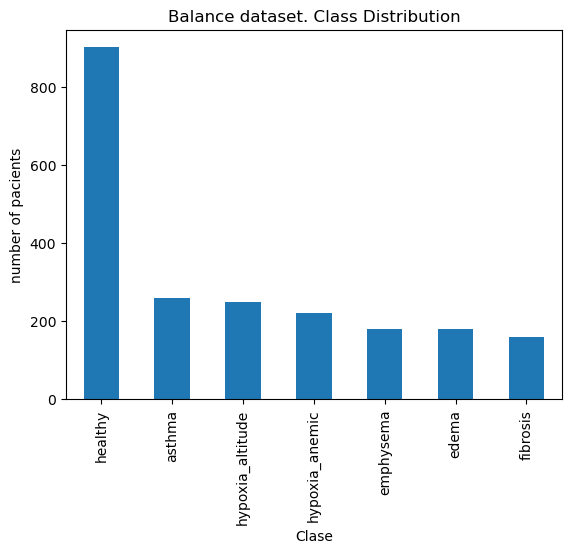

In [5]:
plt.figure()
df["label"].value_counts().plot(kind="bar")
plt.title("Balance dataset. Class Distribution")
plt.xlabel("Clase")
plt.ylabel("number of pacients")
plt.show()


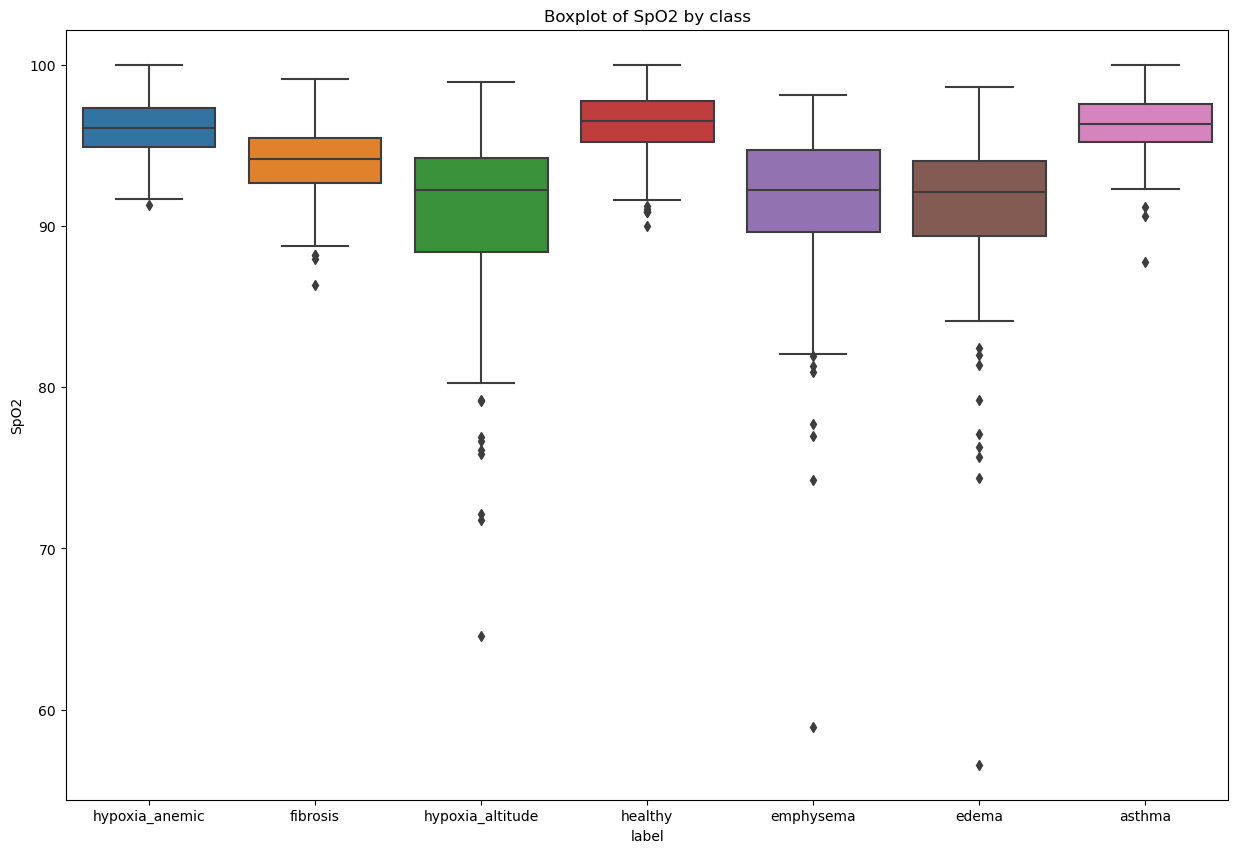

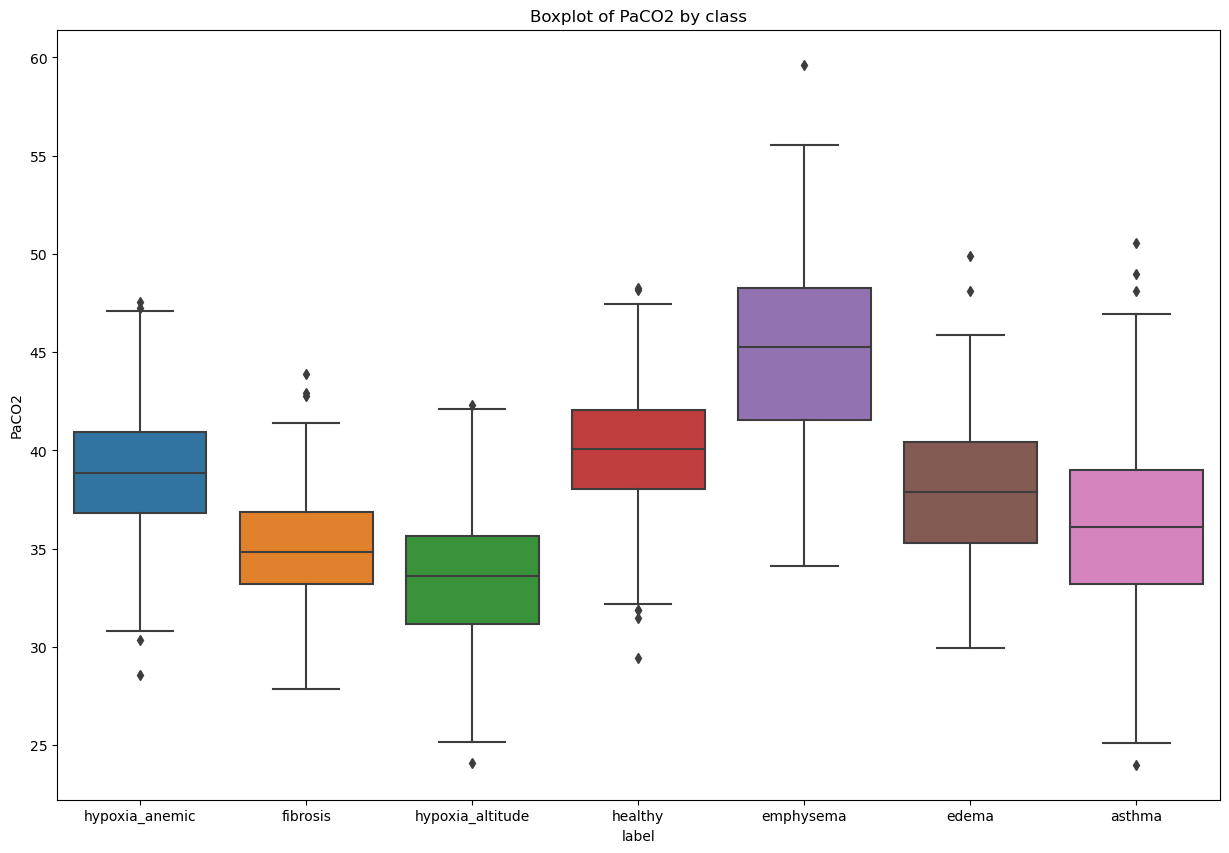

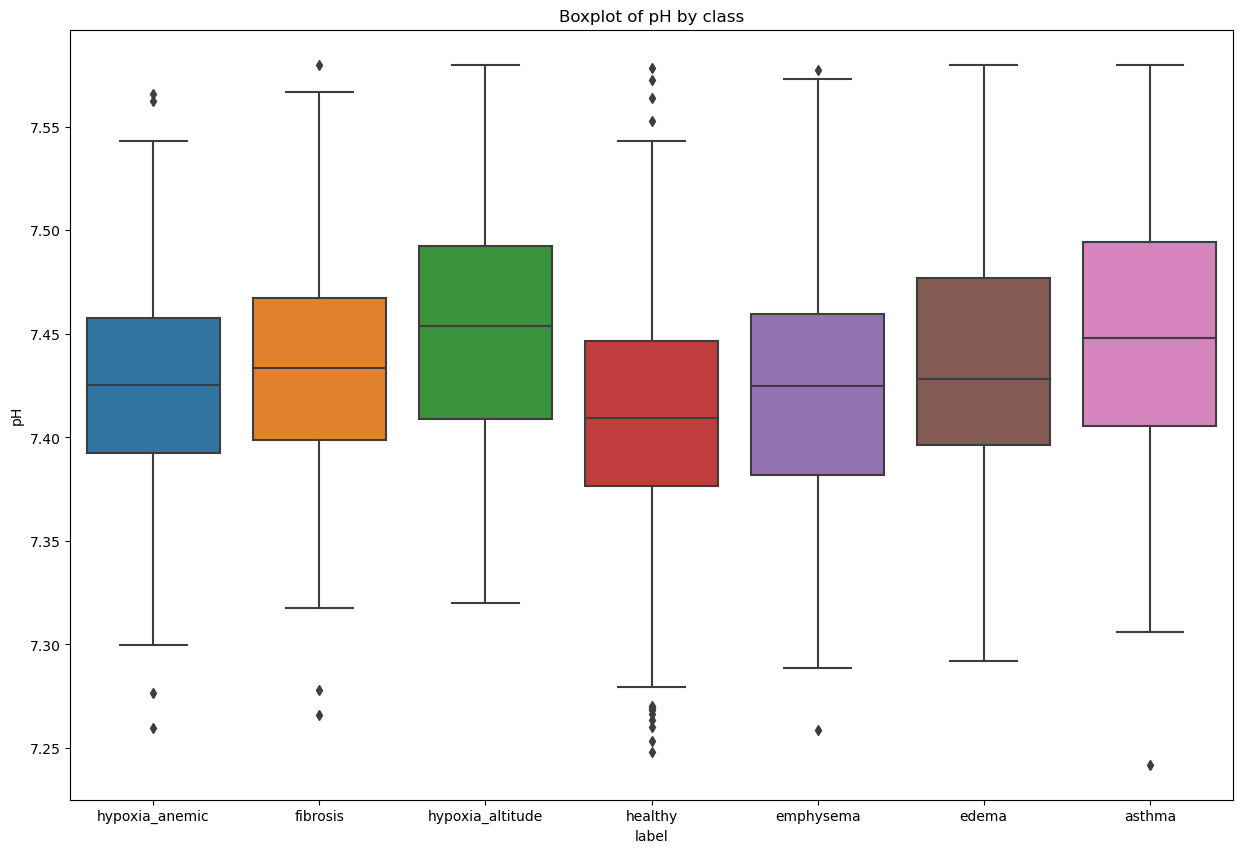

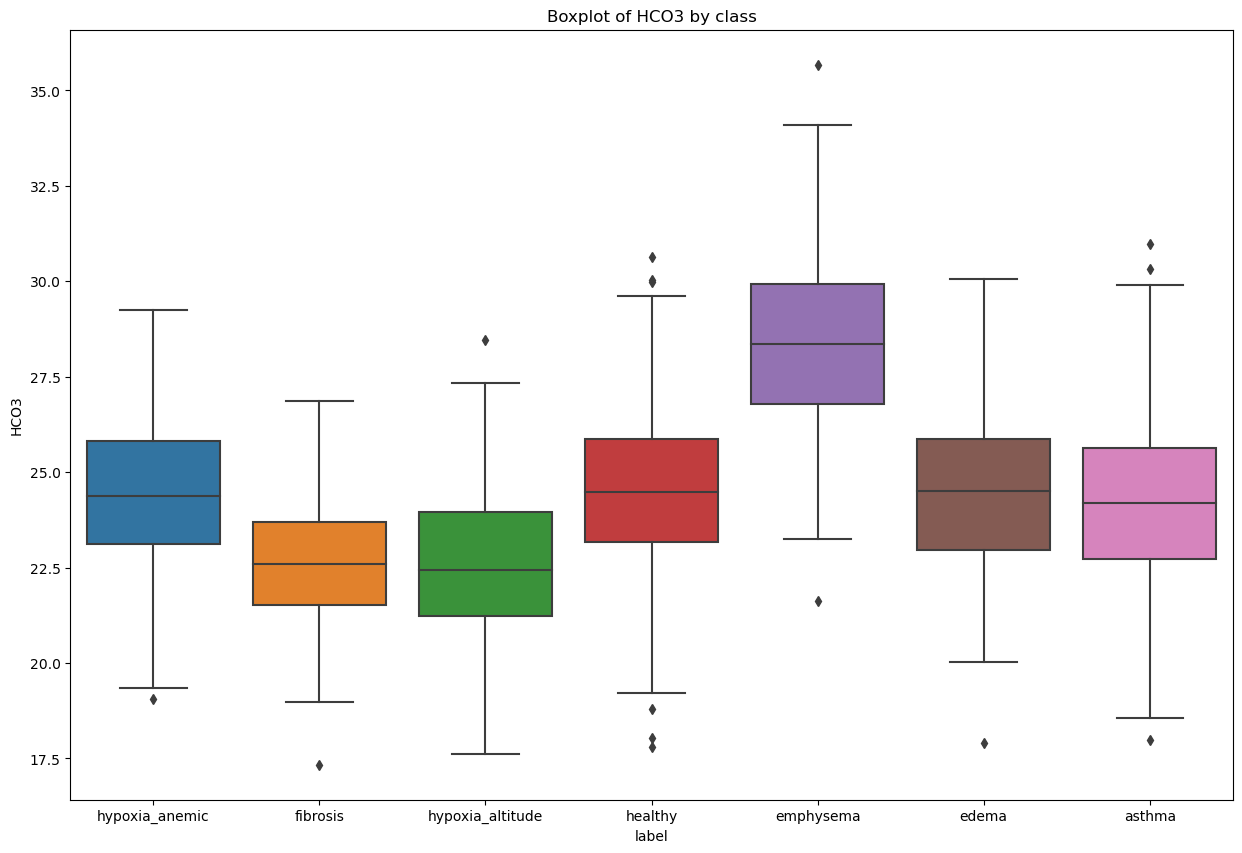

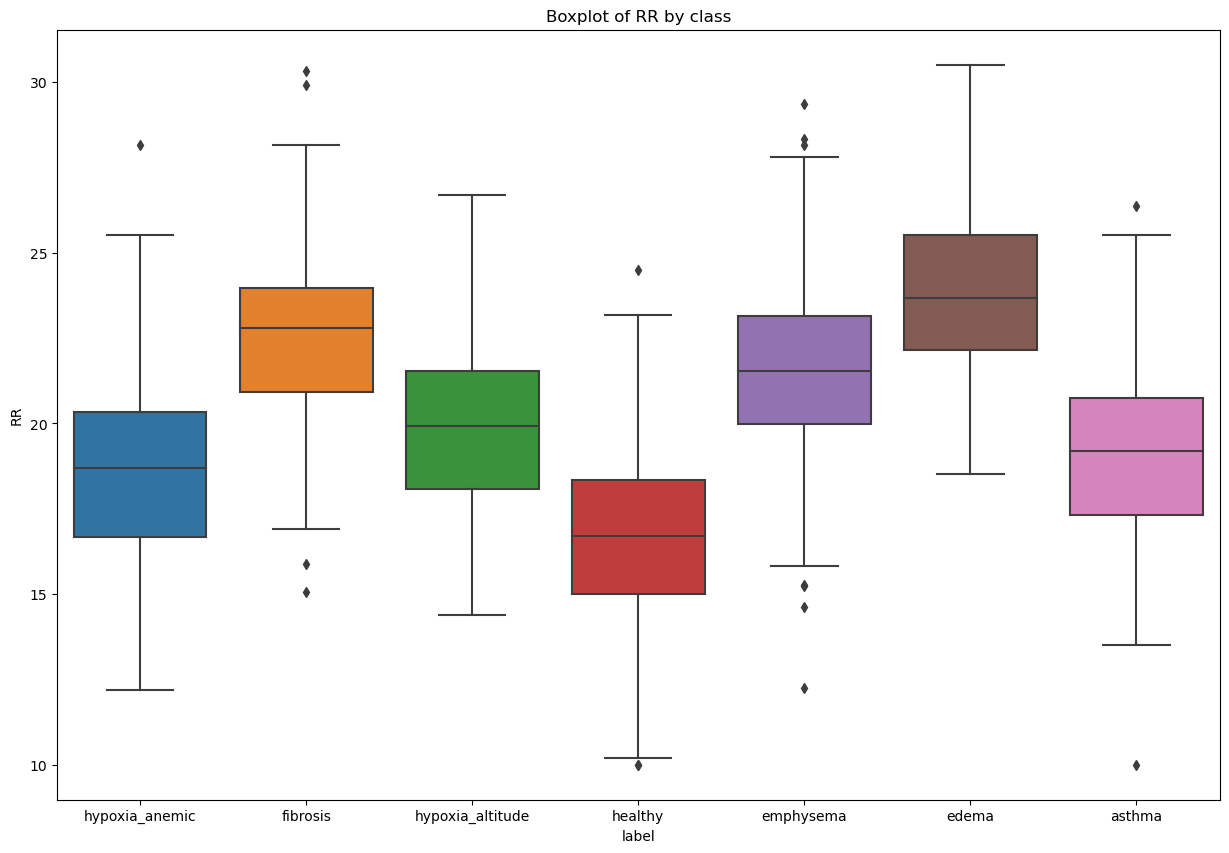

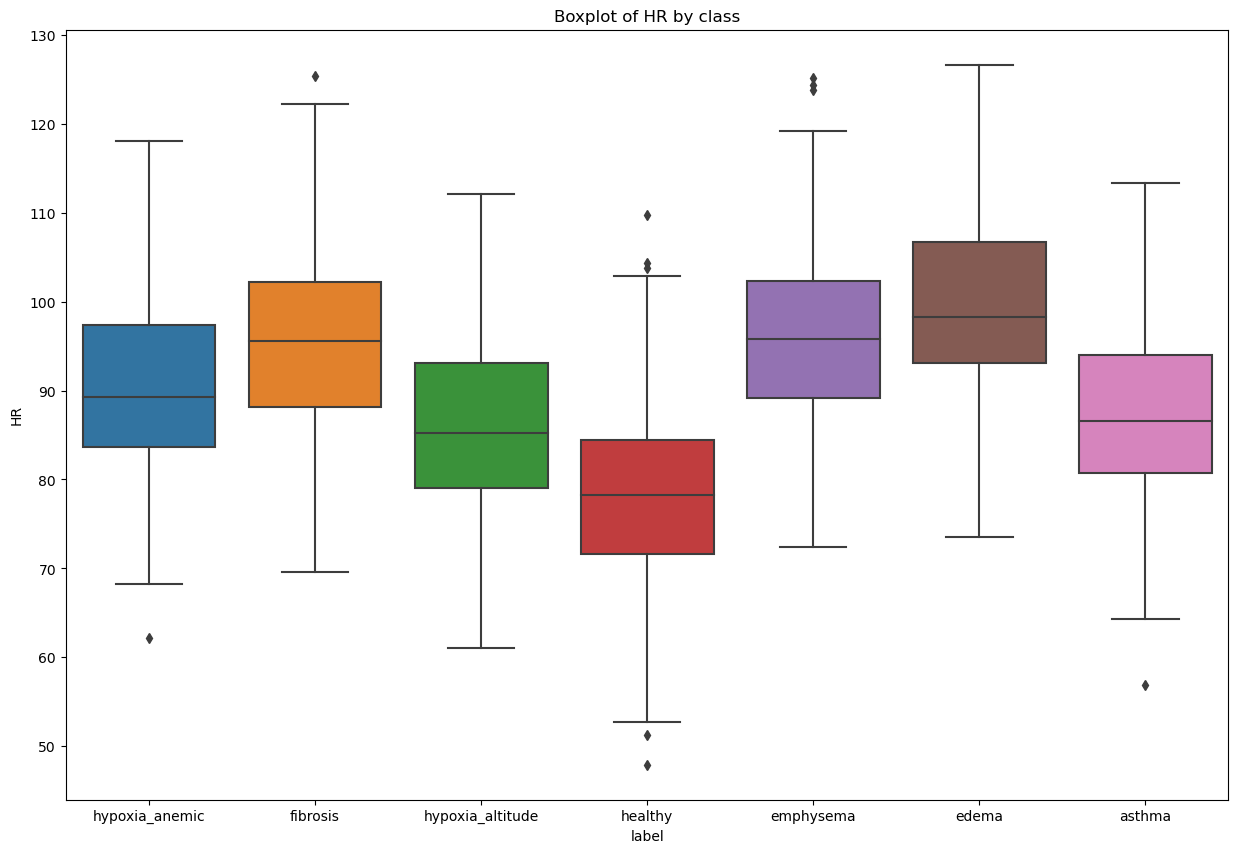

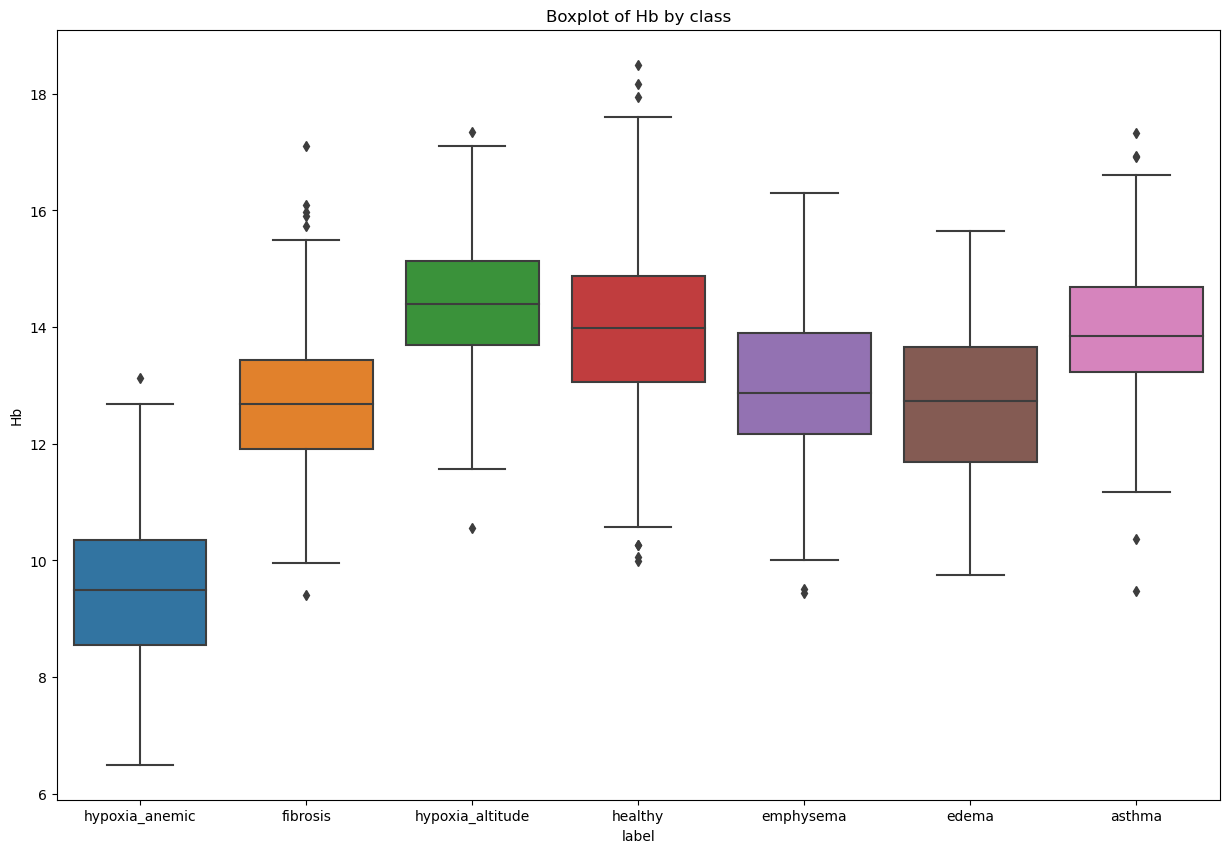

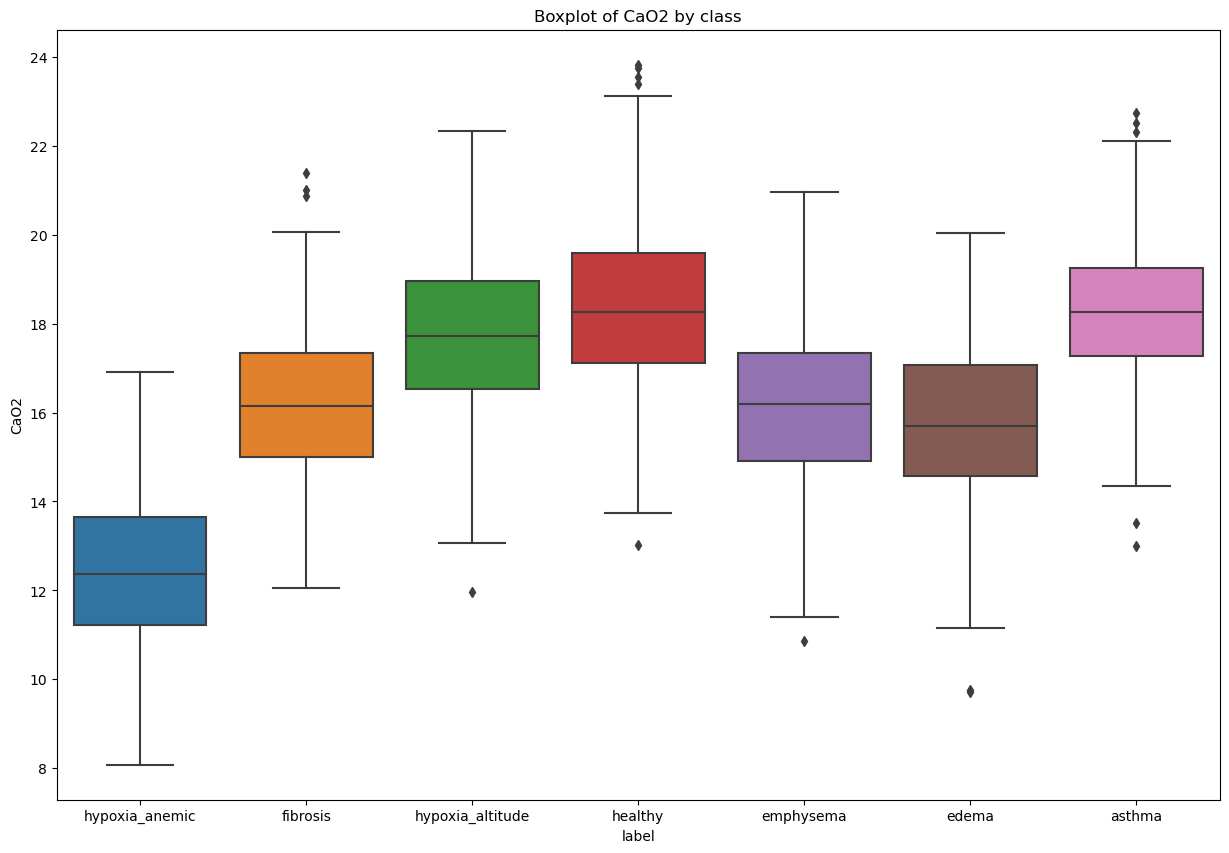

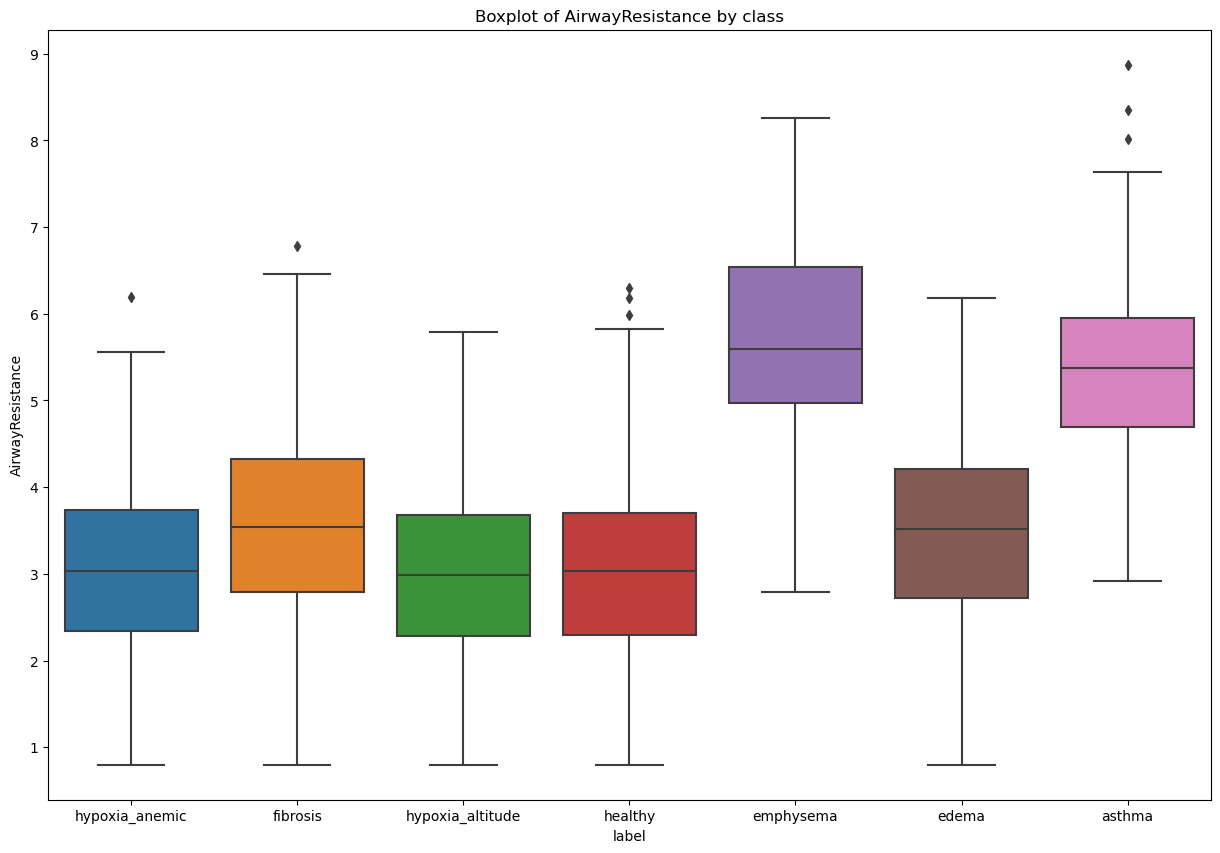

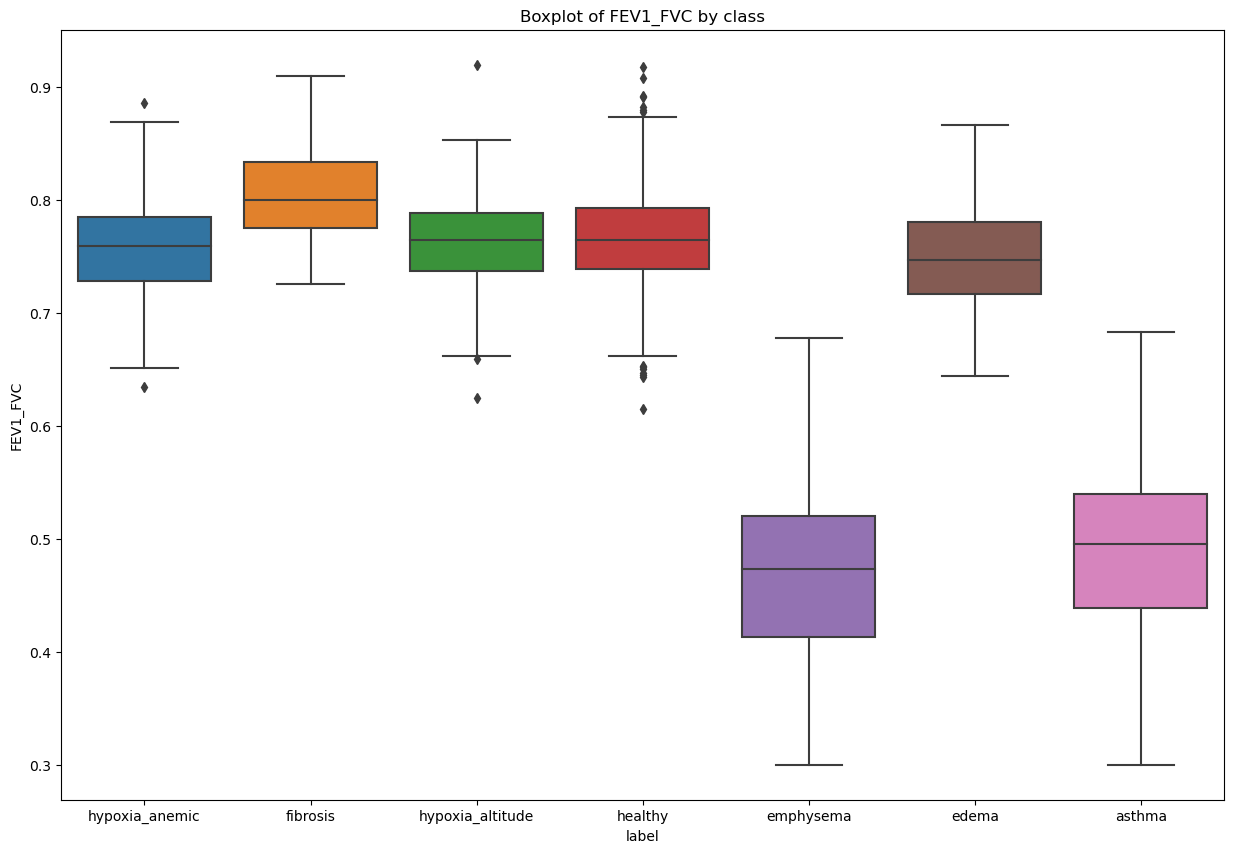

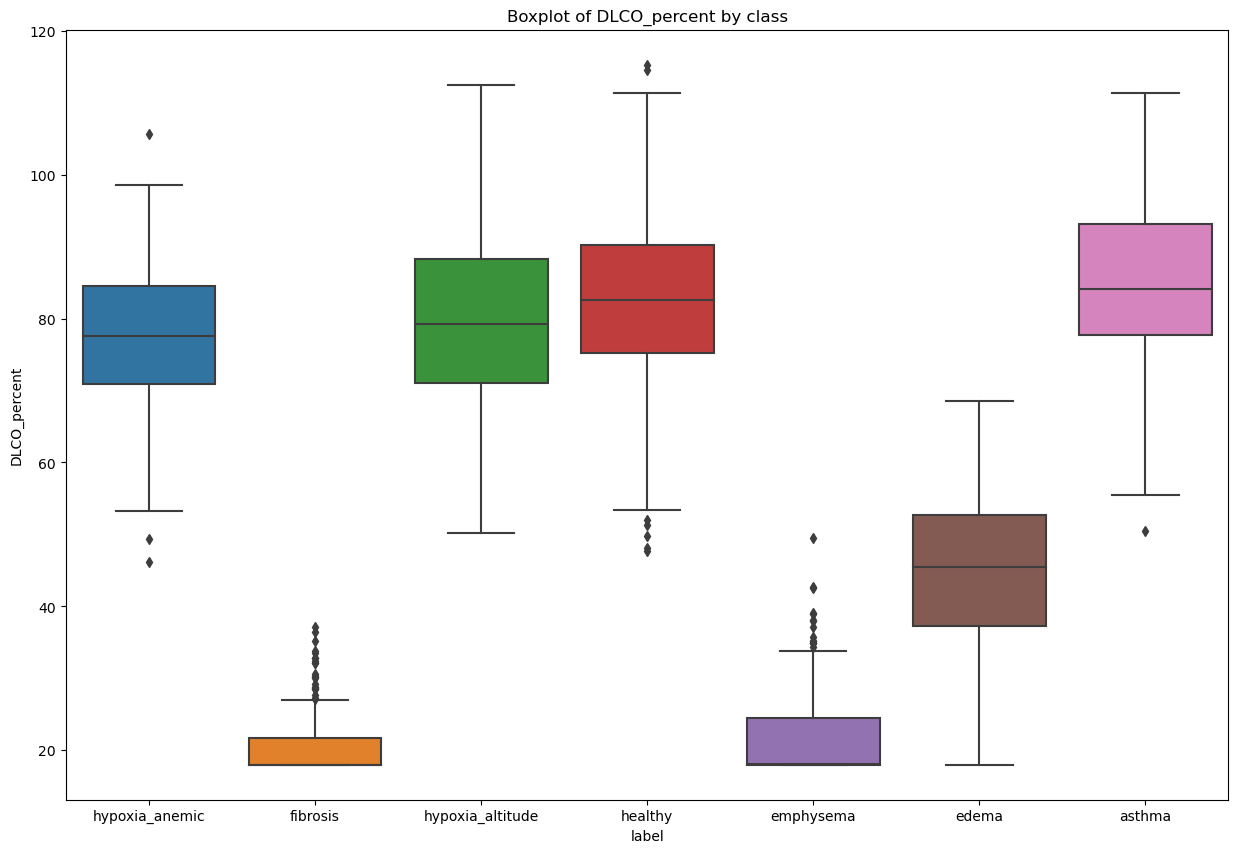

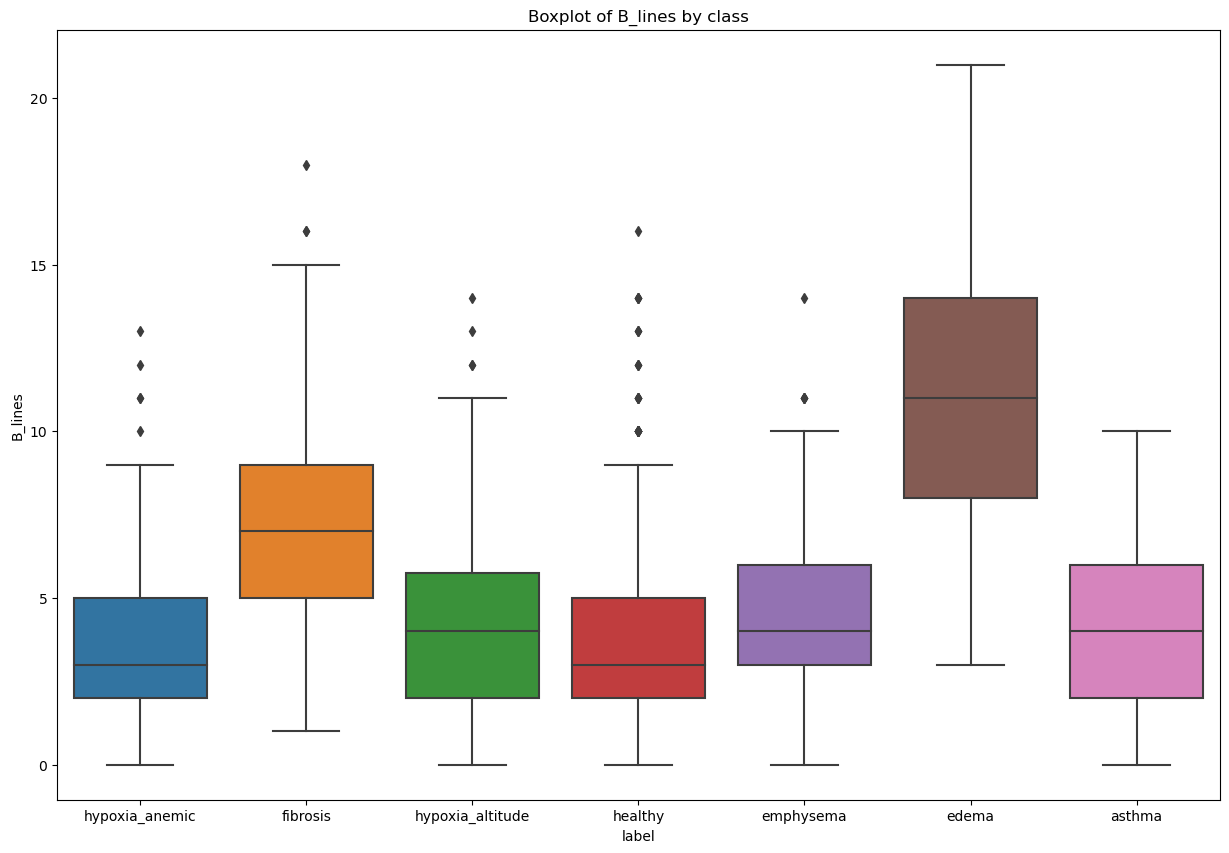

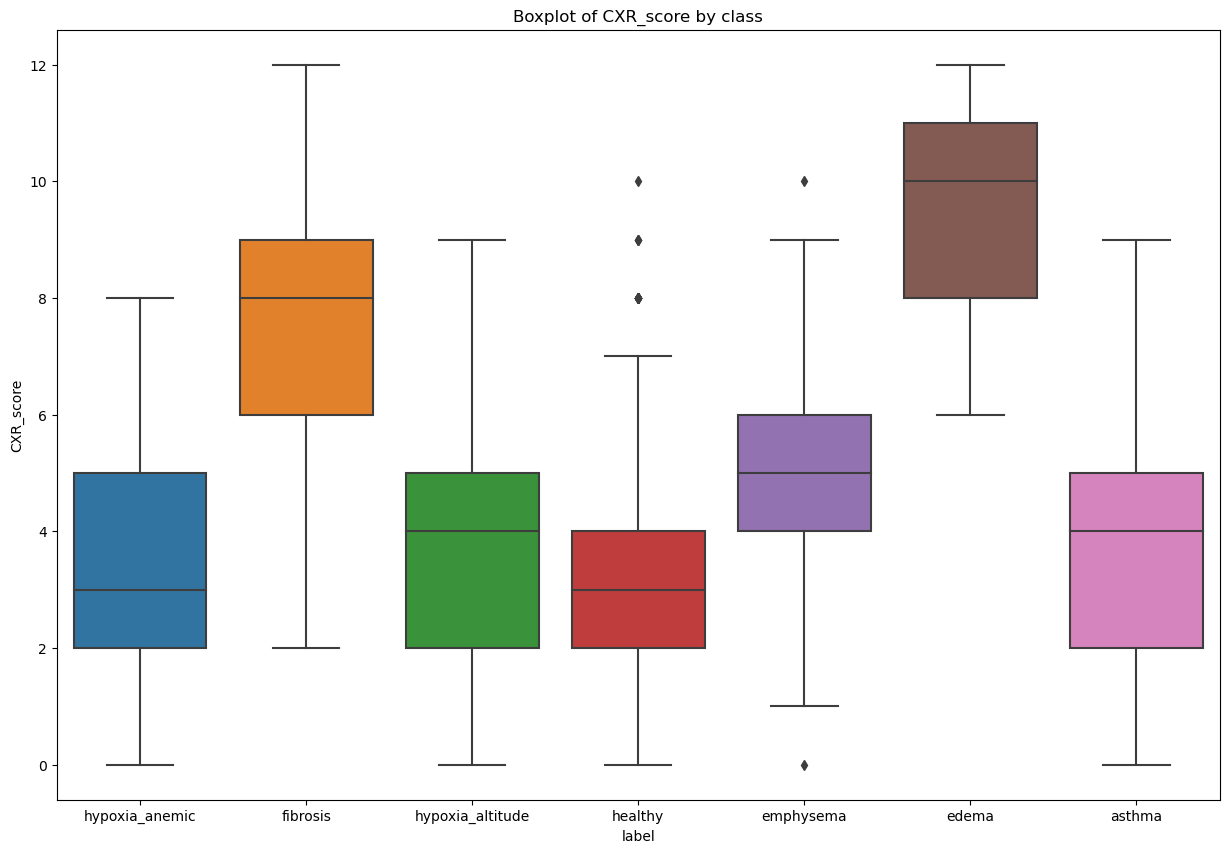

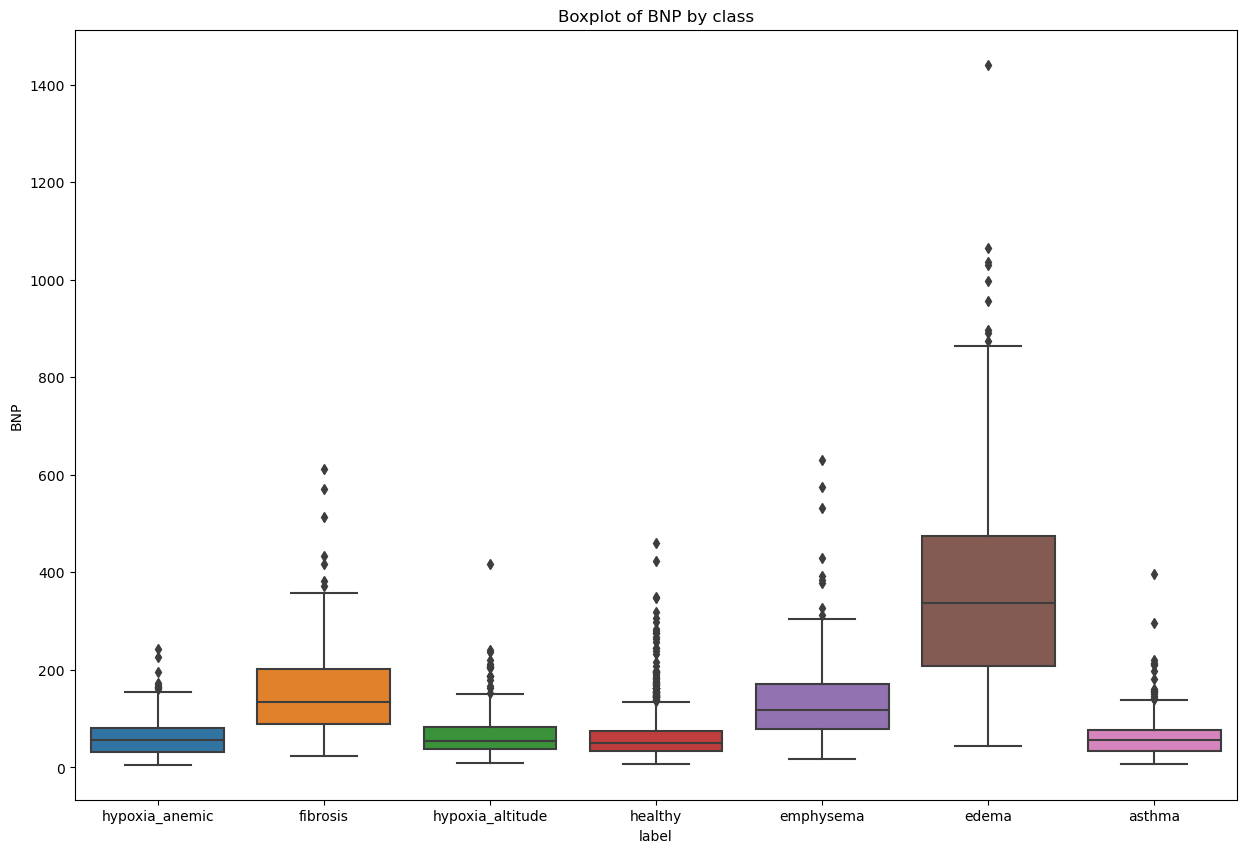

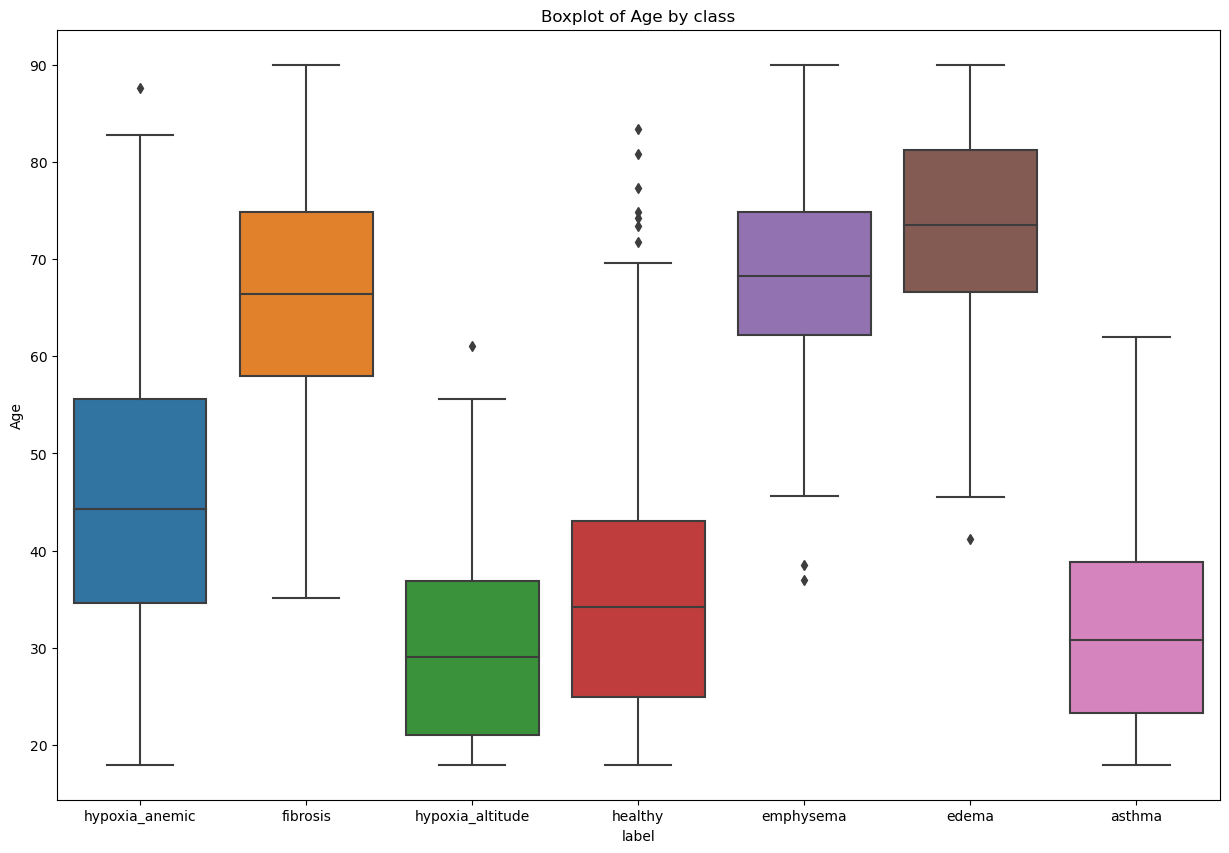

In [6]:
# Updated to your CURRENT features (we do NOT store PaO2, Pbar, PiO2, PAO2)

cols_box = [
    "SpO2",                       # oxygenation
    "PaCO2", "pH", "HCO3",         # ventilation / acid-base
    "RR", "HR",                    # ventilatory + cardiac response
    "Hb", "CaO2",                  # O2 transport (anemia vs hypoxemia)
    "AirwayResistance", "FEV1_FVC",# obstruction markers
    "DLCO_percent",                # diffusion limitation
    "B_lines", "CXR_score",        # imaging / interstitial findings
    "BNP",                         # congestion biomarker
    "Age"                          # demographics
]

for col in cols_box:
    plt.figure(figsize=(15, 10))
    sns.boxplot(data=df, x="label", y=col)
    plt.title(f"Boxplot of {col} by class")

  
    plt.show()


Text(0.5, 1.0, 'HeatMap ')

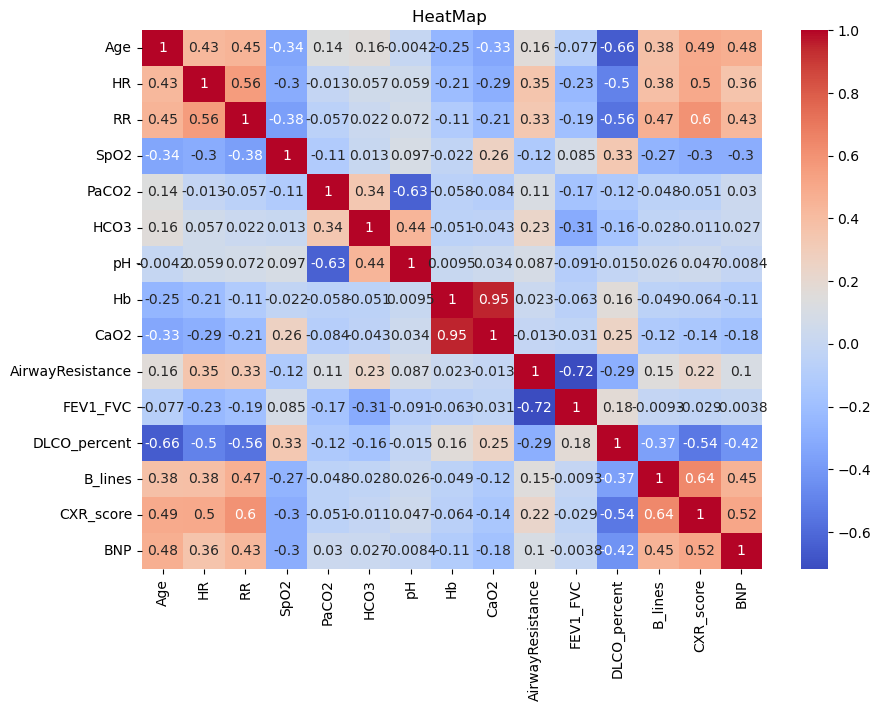

In [7]:
plt.figure(figsize=(10, 7))
features = df.drop(columns=["label"])
corr = features.corr()


sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("HeatMap ")

c:\Users\serpa\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


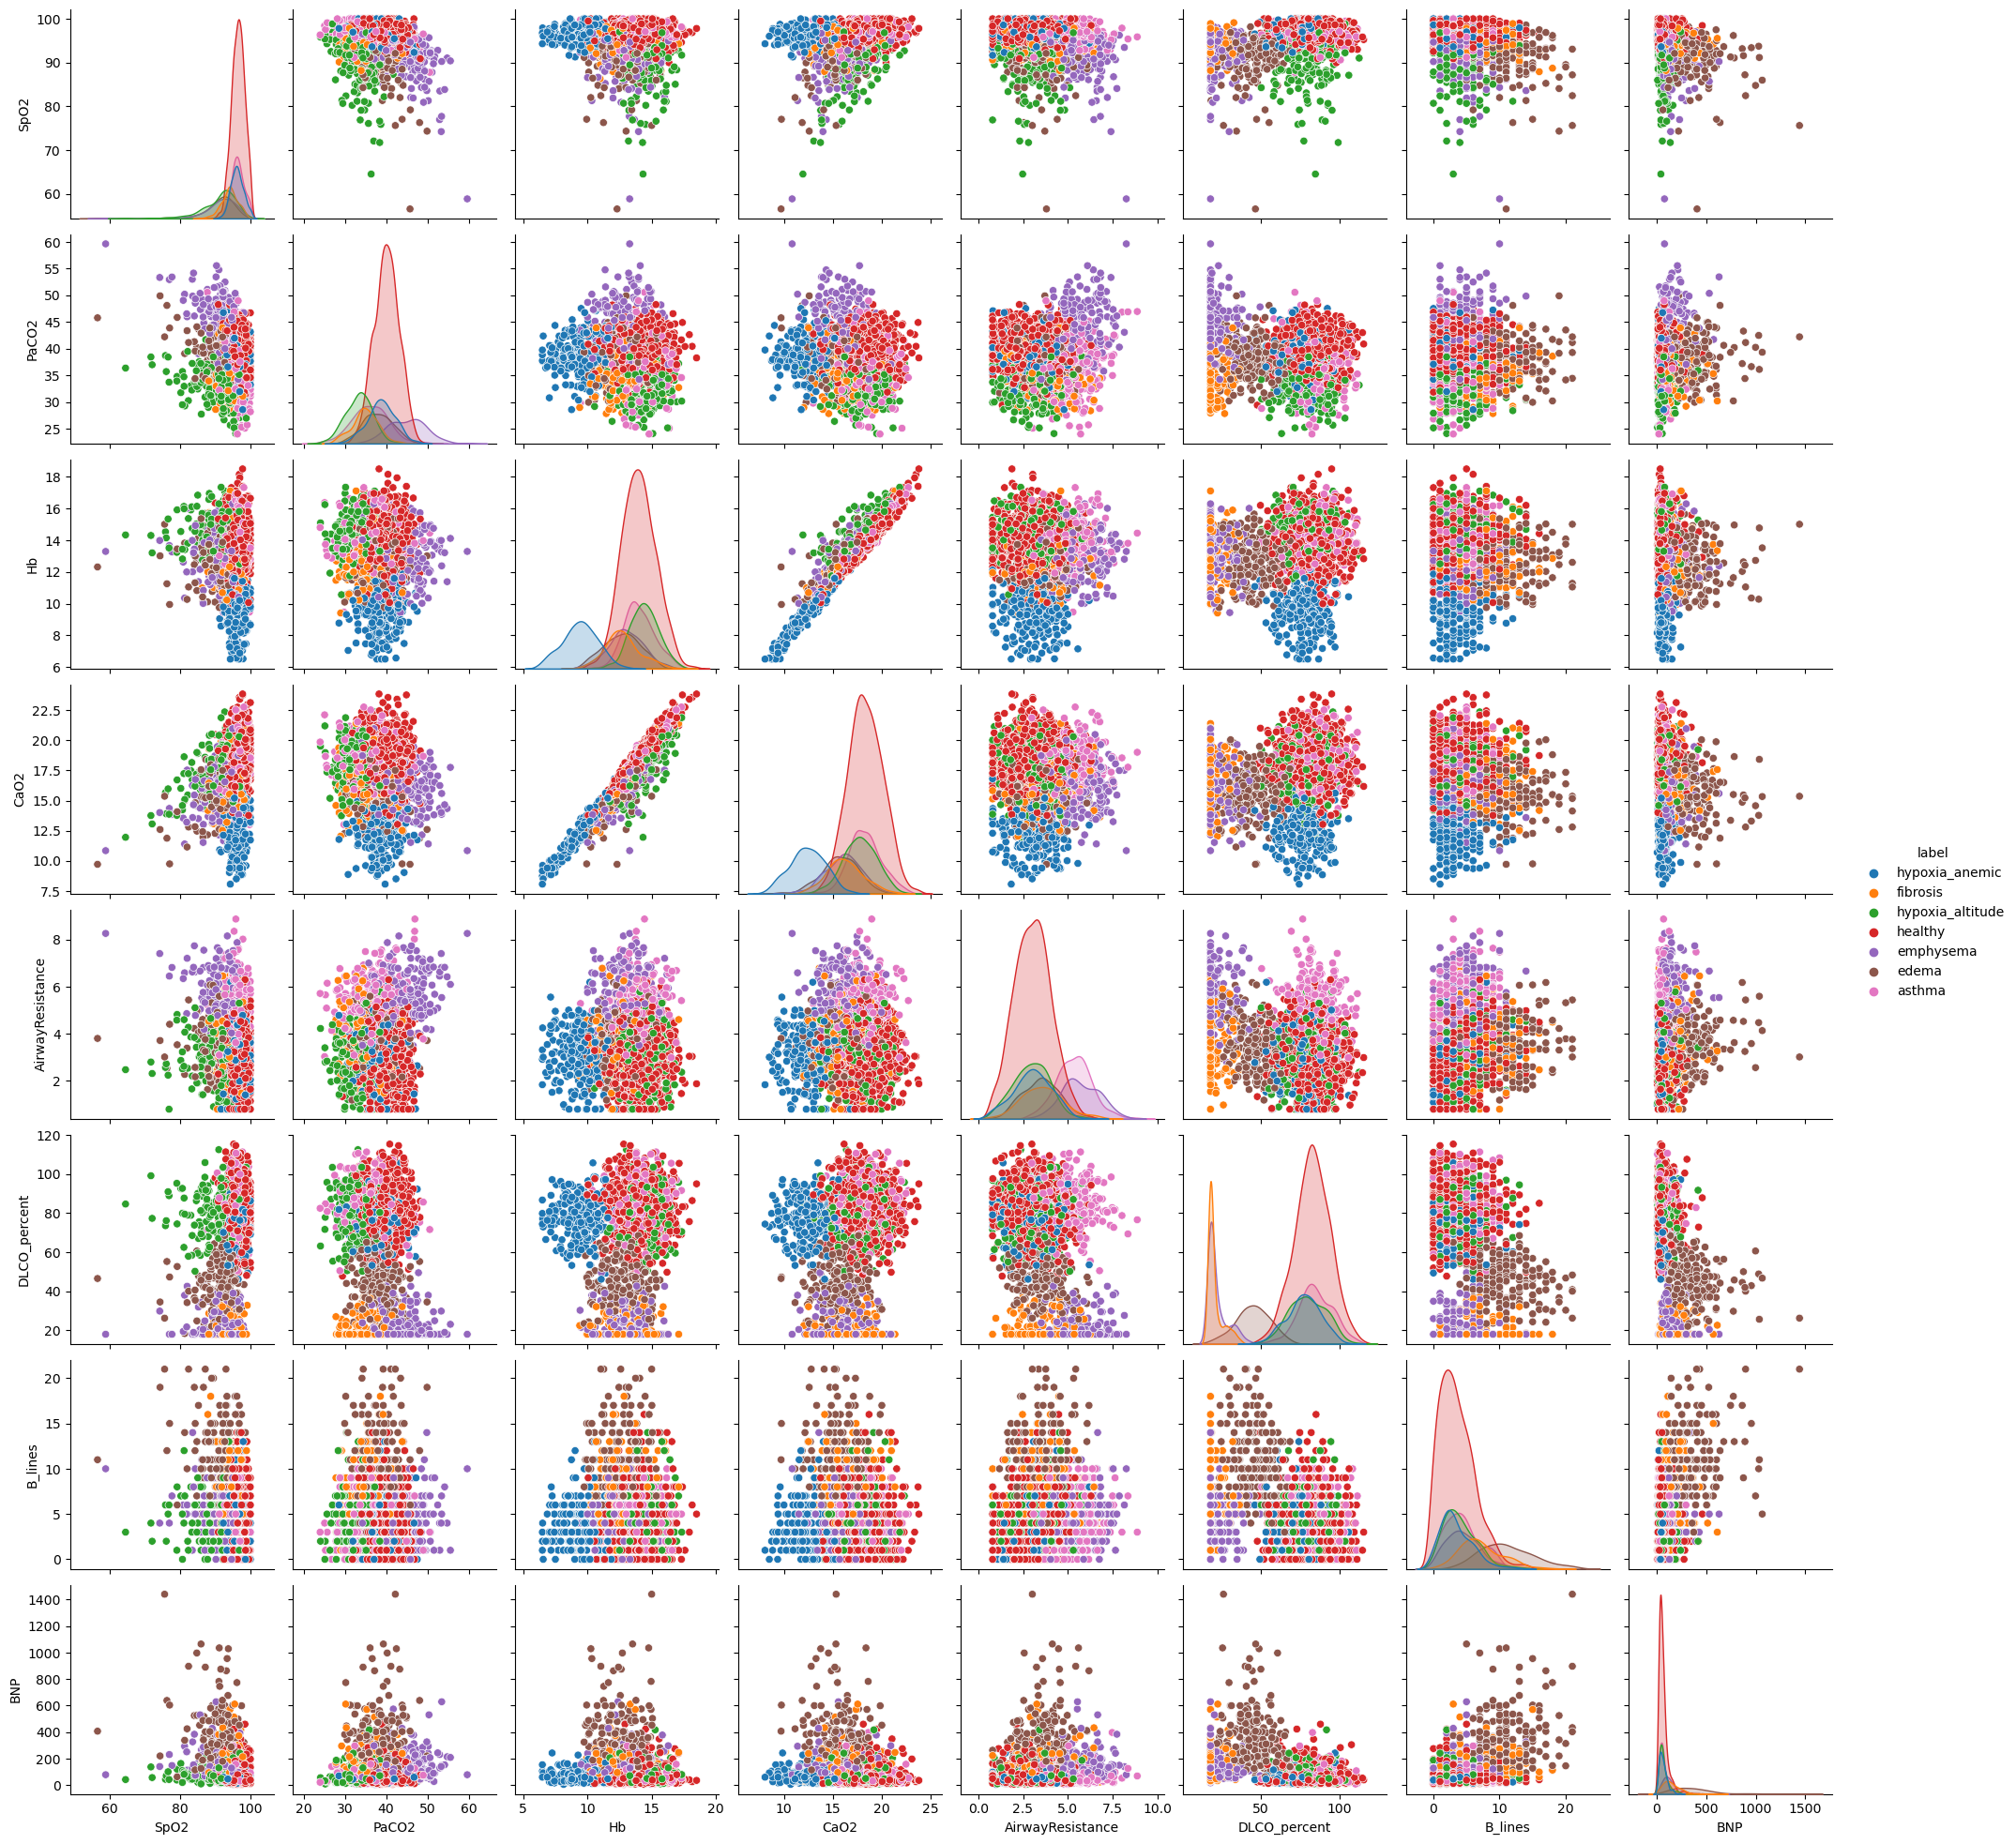

In [8]:

import seaborn as sns
import matplotlib.pyplot as plt

columns = ["SpO2", "PaCO2", "Hb", "CaO2", "AirwayResistance", "DLCO_percent", "B_lines", "BNP"]

g = sns.pairplot(df[columns + ["label"]], hue="label")

plt.show()


In [9]:

import plotly.express as px

df_plot = df.sample(n=min(len(df), 2000), random_state=SEED)

fig = px.scatter(
    df_plot,
    x="PaCO2",
    y="SpO2",
    color="label",
    size="BNP",
    size_max=35,
    opacity=0.7,
    hover_data=["Hb", "CaO2", "B_lines", "CXR_score", "DLCO_percent", "FEV1_FVC", "RR", "HR", "Age"],
    title="SpO2 vs PaCO2 (bubble size = BNP)"
)

fig.show()


## ML: baseline + stronger models

We evaluate several classifiers with:
- train/test split (stratified)
- accuracy + macro-F1
- confusion matrix
- (optional) 5-fold CV macro-F1 for a more stable comparison


In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score


from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import  RandomForestClassifier


train_size = 0.70             
cv = 3                 


In [11]:


scorings = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

target = "label"              
X = df.drop(target, axis=1)   
y = df[target]                


In [12]:

model_lbls = [
    "dt",
    "nb",
    "rf",
]

models = {
    "dt": {
        "name": "Decision Tree",  # nice name to print in results
        "estimator": DecisionTreeClassifier(random_state=SEED),  # the sklearn model
        "param": [{
            "criterion": ["entropy"],            # how to measure split quality
            "max_depth": [*range(1, 20)],        # tree depth (controls overfitting)
            "class_weight": [None, "balanced"],  # helps with imbalanced classes
        }],
    },

    "nb": {
        "name": "Gaussian Naive Bayes",  # nice name to print in results
        "estimator": GaussianNB(),       # Naive Bayes classifier (no random_state)
        "param": [{
            "var_smoothing": [10**exp for exp in range(-3, -13, -1)],  # numeric stability
        }],
    },

    "rf": {
        "name": "Random forest",  # nice name to print in results
        "estimator": RandomForestClassifier(random_state=SEED),  # ensemble of many trees
        "param": [{
            "max_depth": [*range(4, 10)],          # depth of each tree (controls overfitting)
            "n_estimators": [*range(10, 60, 10)],  # number of trees (more = more stable)
        }],
    },
}

In [13]:
#SPLIT TRAIN AND TEST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=train_size, random_state=SEED, stratify=y
)
print(f"\nTraining on {len(X_train)} examples")
print(f"Testing on  {len(X_test)} examples")



Training on 1505 examples
Testing on  645 examples


In [14]:
# GRIDSEARCH: we try many hyperparameter combinations using cross-validation (cv),
# and we keep the best one according to each scoring metric.

clfs = []  # to store every fitted GridSearchCV object

# table to save the test results for each (scoring, model)
results = pd.DataFrame(
    columns=["scoring", "model", "best_params", "accuracy", "precision_macro", "recall_macro", "f1_macro"]
)

for scoring in scorings:            
    for m in model_lbls:            
        clf = GridSearchCV(         
            estimator=models[m]["estimator"],   
            param_grid=models[m]["param"],      
            cv=cv,                               
            scoring=scoring,                     
                                     
        )

        clf.fit(X_train, y_train)   
        clfs.append(clf)            

        y_true = y_test             # true labels (test set)
        y_pred = clf.predict(X_test)# predictions from the best found model

        cr = classification_report( # compute metrics (as a dict)
            y_true, y_pred,
            output_dict=True,       
            zero_division=1         # avoid errors when a class has no predicted samples
        )

        results.loc[len(results)] = [                 # add one row to the results table
            scoring,                                  # which scoring we optimized
            models[m]["name"],                        # model name
            clf.best_params_,                         # best hyperparameters found in CV
            cr["accuracy"],                           # test accuracy
            cr["macro avg"]["precision"],             # macro-precision on test
            cr["macro avg"]["recall"],                # macro-recall on test
            cr["macro avg"]["f1-score"],              # macro-F1 on test
        ]


c:\Users\serpa\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\serpa\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\serpa\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\Users\serpa\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1469: UndefinedMetricWarning:

Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.

c:\U

In [15]:
for score in scorings:
    scoring_filter = score
    display(
        results[results.scoring == scoring_filter]
        .sort_values(by=scoring_filter, ascending=False) #SORT BY THE BEST 
        .style.format(precision=3) #THE NUMBER OF DECIMALS
        .set_caption(f'Results for scoring "{scoring_filter}"')
    )


,scoring,model,best_params,accuracy,precision_macro,recall_macro,f1_macro
1,accuracy,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.963,0.959,0.969,0.964
2,accuracy,Random forest,"{'max_depth': 9, 'n_estimators': 50}",0.960,0.956,0.964,0.960
0,accuracy,Decision Tree,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 9}",0.927,0.924,0.929,0.926


,scoring,model,best_params,accuracy,precision_macro,recall_macro,f1_macro
4,precision_macro,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.963,0.959,0.969,0.964
5,precision_macro,Random forest,"{'max_depth': 8, 'n_estimators': 20}",0.953,0.954,0.952,0.953
3,precision_macro,Decision Tree,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 7}",0.927,0.919,0.932,0.925


,scoring,model,best_params,accuracy,precision_macro,recall_macro,f1_macro
7,recall_macro,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.963,0.959,0.969,0.964
8,recall_macro,Random forest,"{'max_depth': 9, 'n_estimators': 50}",0.960,0.956,0.964,0.960
6,recall_macro,Decision Tree,"{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 8}",0.904,0.896,0.929,0.911


,scoring,model,best_params,accuracy,precision_macro,recall_macro,f1_macro
10,f1_macro,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.963,0.959,0.969,0.964
11,f1_macro,Random forest,"{'max_depth': 9, 'n_estimators': 50}",0.960,0.956,0.964,0.960
9,f1_macro,Decision Tree,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 9}",0.927,0.924,0.929,0.926


## Variable importance & interpretation

We show:
- **Permutation importance** for the best model (test set).
- If the best model is tree-based, also `feature_importances_`.
- For logistic regression, coefficient magnitudes (after scaling).


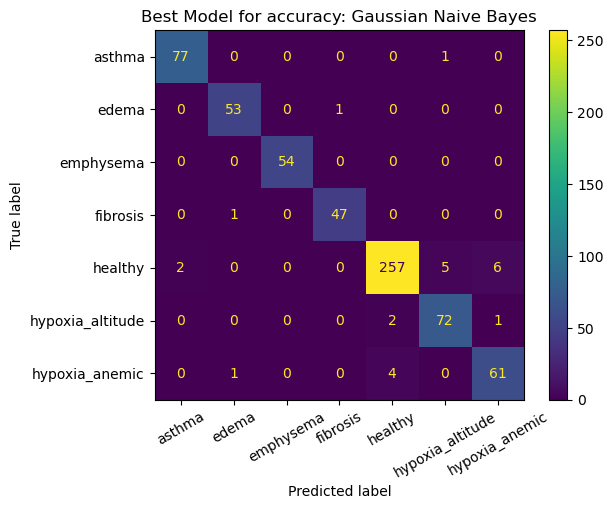

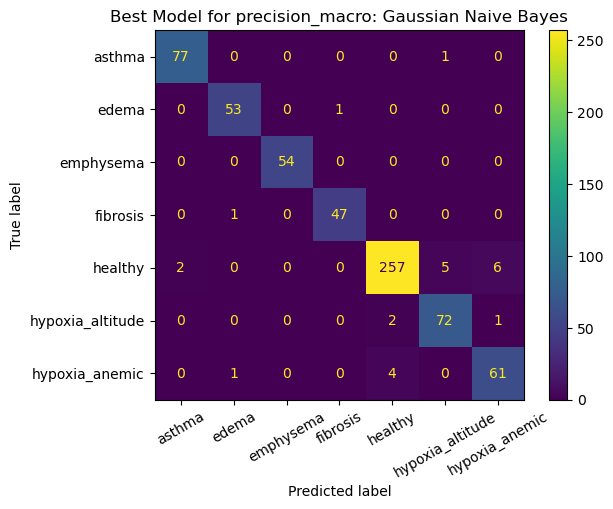

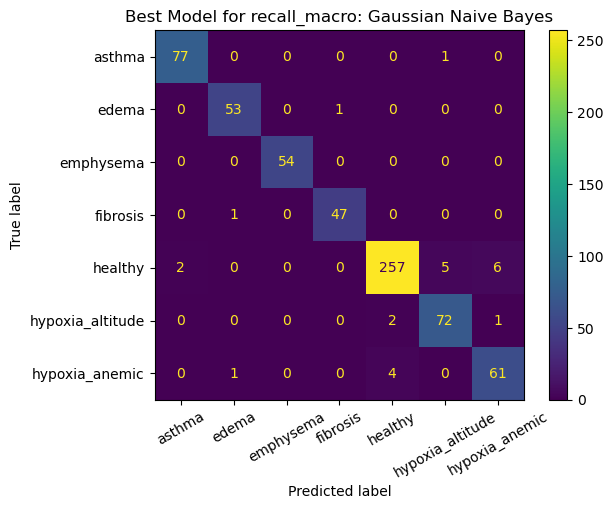

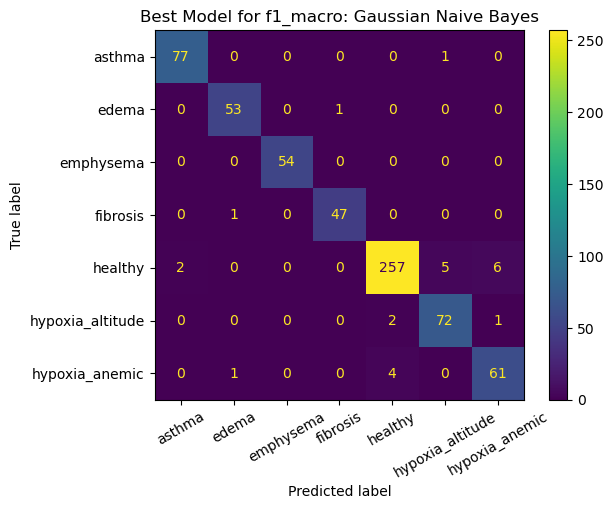

In [16]:
for score in scorings:
    scoring_filter = score
    best_row = results.loc[results.scoring == scoring_filter, scoring_filter].idxmax(axis=0)

    disp = ConfusionMatrixDisplay.from_estimator(
        estimator=clfs[best_row],
        X=X_test,
        y=y_test,
        xticks_rotation=30
    )
    disp.ax_.set_title(f"Best Model for {score}: {results.at[best_row, 'model']}")
    plt.show()
